In [3]:
import numpy as np
import scipy.stats

import matplotlib.pyplot as plt

In [4]:
import sys

sys.path.insert(
0,
"/Users/fabiojv/Documents/Studium/Repositories/Bayesian-Stats-HS2026/course_tools/src"
)

In [5]:
title = "# Sampling 1: Exercises"
# Print title and setup TeX defs for both KaTeX and MathJax
import bayesian_stats_course_tools
bayesian_stats_course_tools.misc.display_markdown_and_setup_tex(title)

import matplotlib.style
matplotlib.style.use("bayesian_stats_course_tools.light")

# Sampling 1: Exercises

<!-- Define LaTeX macros -->
$\def\E{\operatorname{E}}$
$\def\Var{\operatorname{Var}}$
$\def\Cov{\operatorname{Cov}}$
$\def\dd{\mathrm{d}}$
$\def\ee{\mathrm{e}}$
$\def\Norm{\mathcal{N}}$
$\def\Uniform{\mathcal{U}}$
$\def\GP{\mathcal{GP}}$

<!-- MathJax needs them to be defined again for the non-inline environment -->
$$\def\E{\operatorname{E}}$$
$$\def\Var{\operatorname{Var}}$$
$$\def\Cov{\operatorname{Cov}}$$
$$\def\dd{\mathrm{d}}$$
$$\def\ee{\mathrm{e}}$$
$$\def\Norm{\mathcal{N}}$$
$$\def\Uniform{\mathcal{U}}$$
$$\def\GP{\mathcal{GP}}$$

### Exercise

Implement your own rejection sampling routine and test it with different target and proposal distributions.

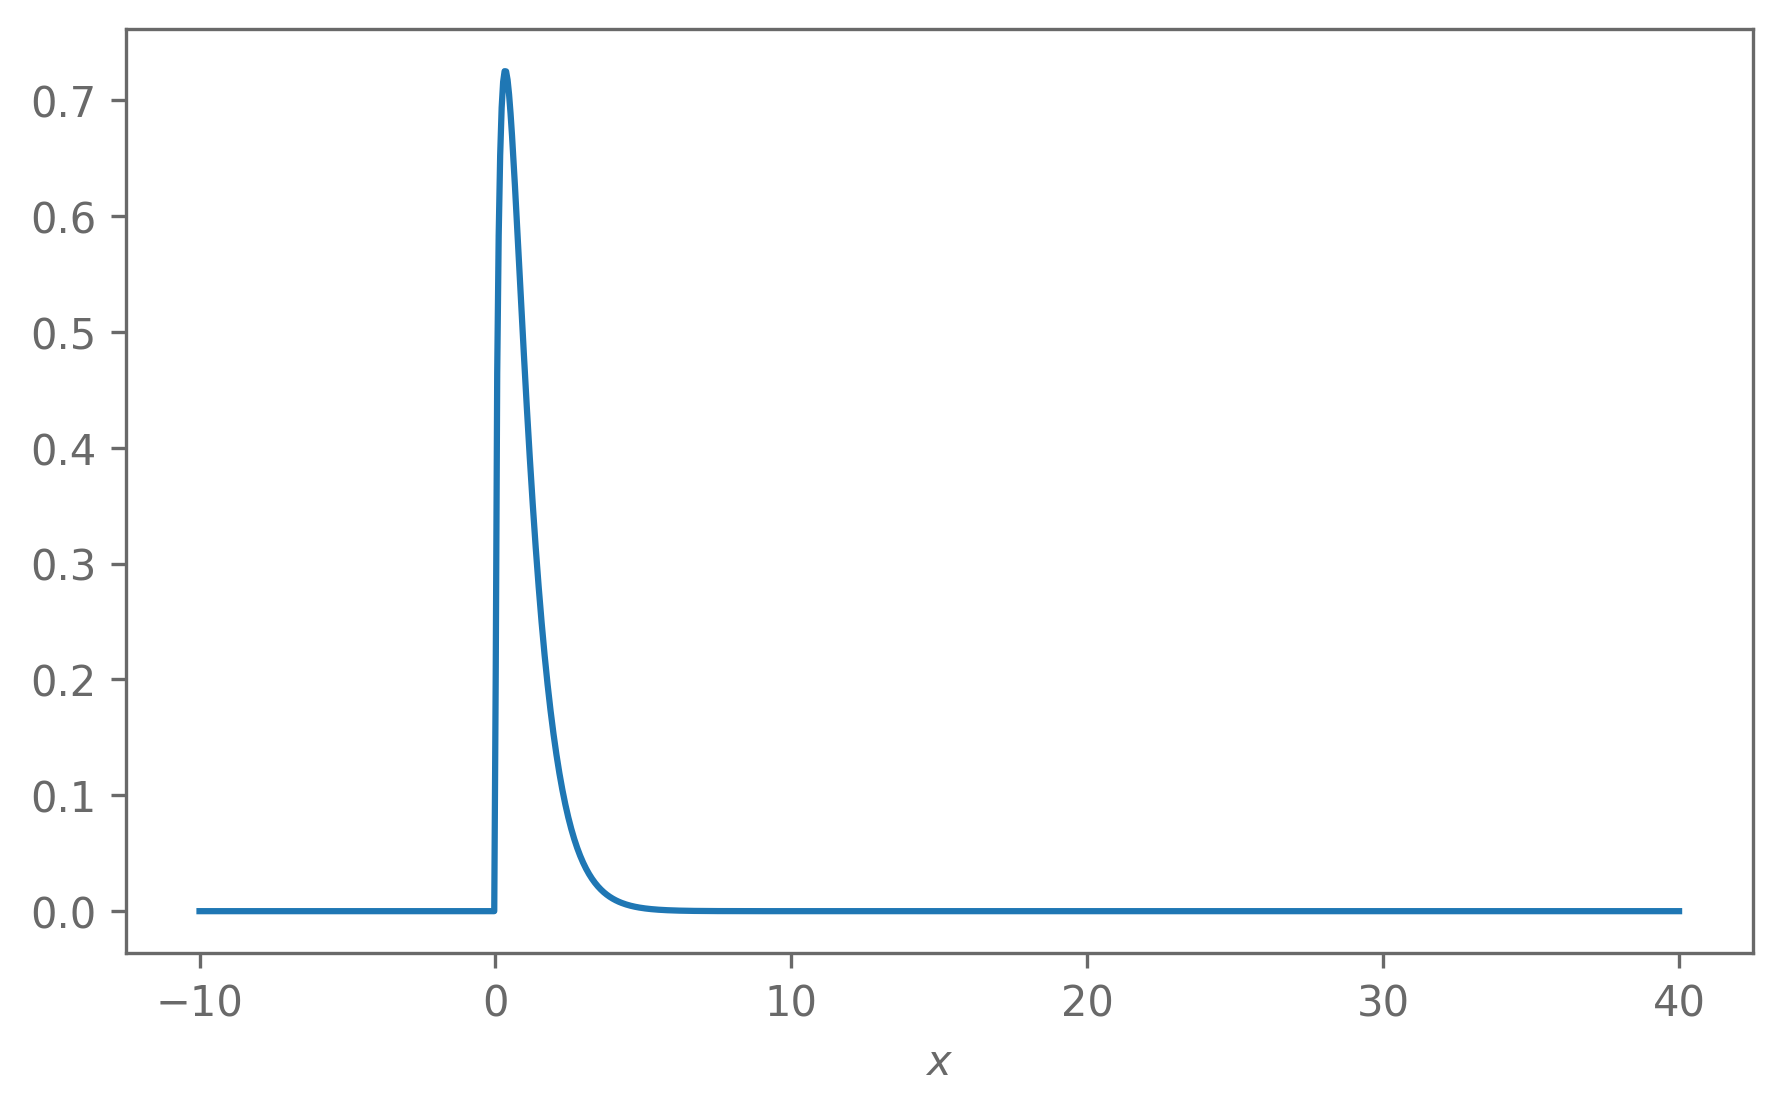

In [21]:
target_distr = scipy.stats.chi2(df=3, scale=1/3)

grid = np.linspace(-10, 40, 1000)
plt.plot(grid, target_distr.pdf(grid))
plt.xlabel("$x$");

In [22]:
# We use a Gaussian as our proposal distribution q and set M to 3
proposal_distr = scipy.stats.norm(loc=0.5, scale=1.2)
M = 3

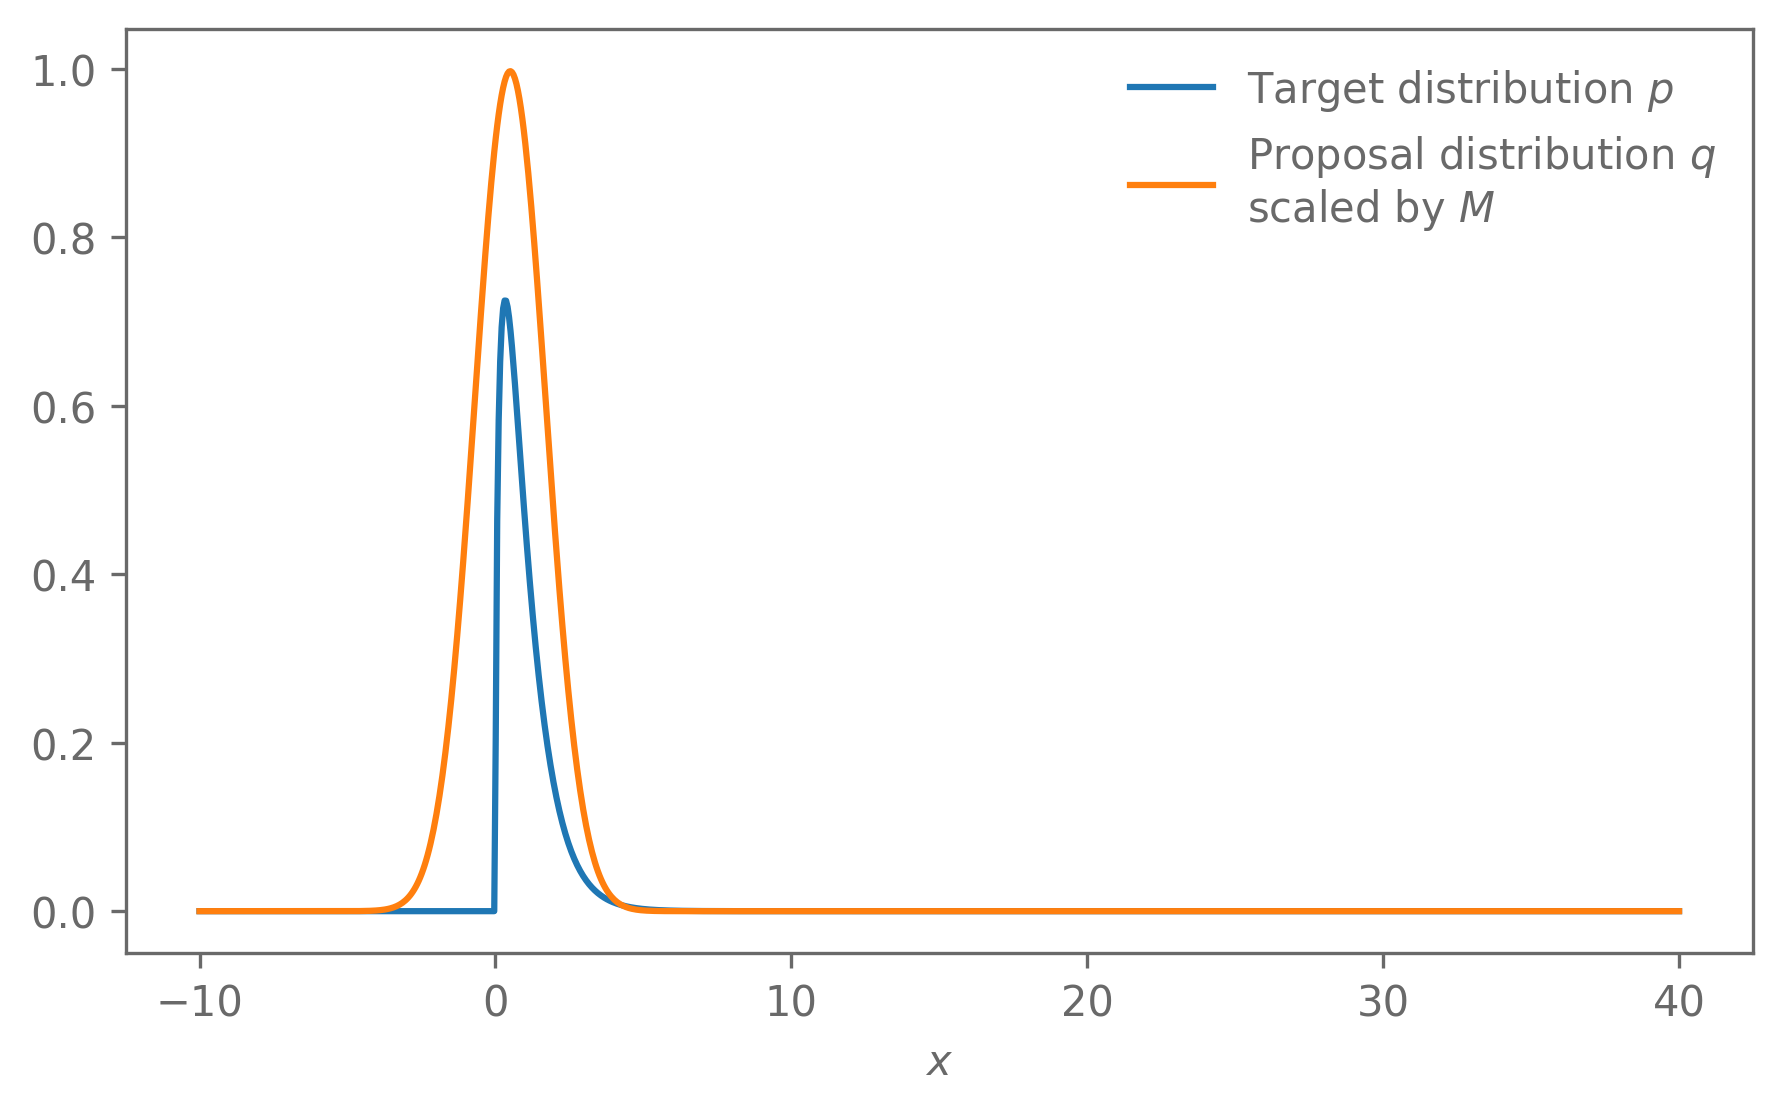

In [23]:
plt.plot(grid, target_distr.pdf(grid), label="Target distribution $p$")
plt.plot(grid, M*proposal_distr.pdf(grid), label="Proposal distribution $q$\nscaled by $M$")
plt.xlabel("$x$")
plt.legend(frameon=False);

In [ ]:
def rejection_sampling(n):
    samples_generated = 0
        rejections = 0
        while samples_generated < n:
            x = proposal_distr.rvs(size=1)
            u = np.random.uniform(size=1)
    
            f = target_distr.pdf(x)
            g = proposal_distr.pdf(x)
    
            if u < f/(M*g):
                samples_generated += 1
                yield x
            else:
                rejections += 1
    
        acceptance_rate = samples_generated/(samples_generated+rejections)
        print(f"Acceptance rate: {acceptance_rate}")

### Exercise

- Implement Metropolis-Hastings for $n$ dimensional distributions
    - Sample from a 2D Gaussian (code on the next slide)
    - Plot the samples in the chain. How do the samples depend on the starting position?
- Show that Metropolis-Hastings satisfies detailed balance
    - Hint: $T(x|y) = q(x|y)\min(1, a)$

In [2]:
# Define variances and correlation
sigma_x = 1
sigma_y = 2
rho = 0.7

# Define mean and covariance
mean = np.array([1, 0.5])
cov = np.array([[sigma_x**2, sigma_x*sigma_y*rho],
                [sigma_x*sigma_y*rho, sigma_y**2]])

# Create distribution object
bivariate_normal = scipy.stats.multivariate_normal(mean=mean, cov=cov)

# Sample 1000 points. Do this with your MCMC implementation instead!
samples = bivariate_normal.rvs(size=1000)

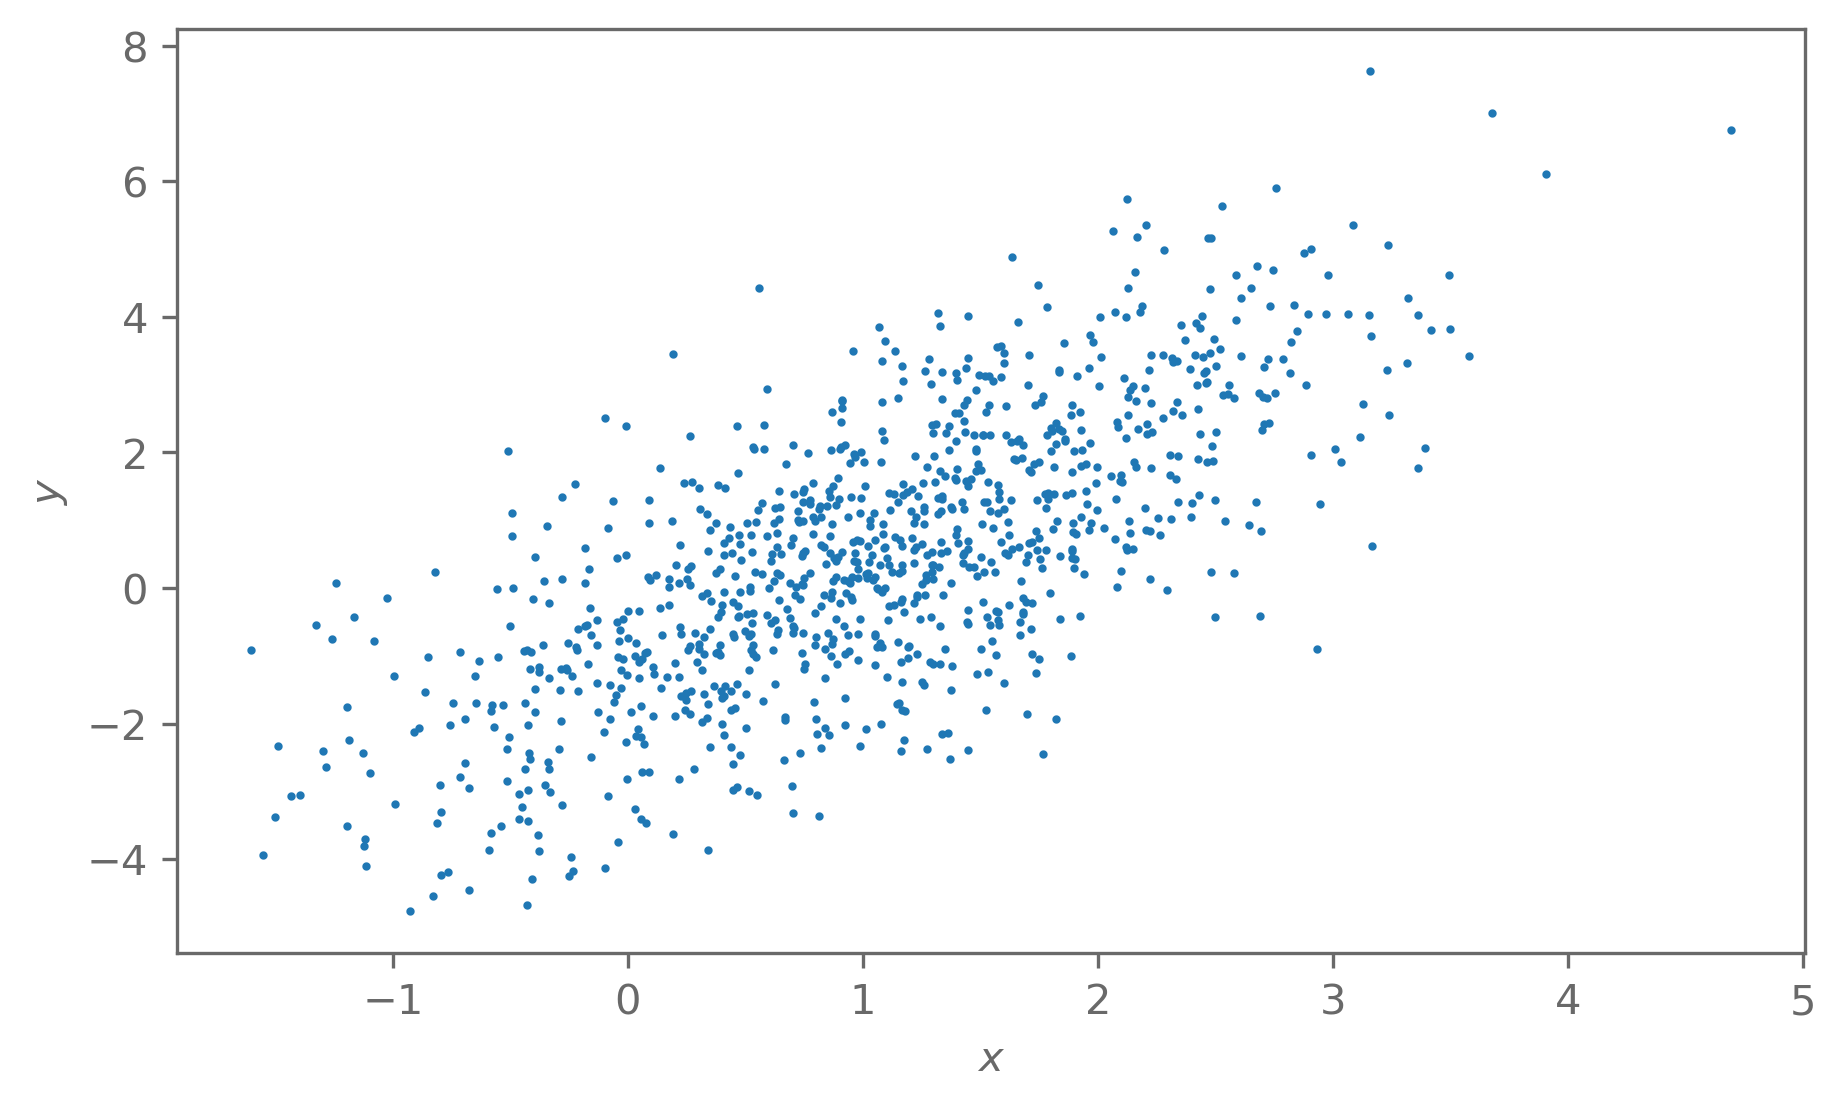

In [ ]:
plt.scatter(*samples.T, s=1)
plt.ylabel("$y$")
plt.xlabel("$x$");